In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)
from xgboost import XGBClassifier

df = pd.read_csv("data/paysim.csv")
df = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
print(df.shape)
print(f"Taux de fraude : {df['isFraud'].mean() * 100:.3f} %")

(2770409, 11)
Taux de fraude : 0.296 %


In [3]:
def build_features(d):
    X = pd.DataFrame(index=d.index)
    X["is_transfer"] = (d["type"] == "TRANSFER").astype(int)
    X["amount"] = d["amount"]
    X["old_balance_orig"] = d["oldbalanceOrg"]
    X["new_balance_orig"] = d["newbalanceOrig"]
    X["old_balance_dest"] = d["oldbalanceDest"]
    X["new_balance_dest"] = d["newbalanceDest"]
    # Écart entre le solde attendu et le solde réel
    X["error_balance_orig"] = d["newbalanceOrig"] + d["amount"] - d["oldbalanceOrg"]
    X["error_balance_dest"] = d["oldbalanceDest"] + d["amount"] - d["newbalanceDest"]
    X["hour"] = d["step"] % 24
    return X

X = build_features(df)
y = df["isFraud"]
FEATURES = list(X.columns)
X.head()

,is_transfer,amount,old_balance_orig,new_balance_orig,old_balance_dest,new_balance_dest,error_balance_orig,error_balance_dest,hour
2,1,181.00,181.0,0.0,0.0,0.00,0.00,181.0,1
3,0,181.00,181.0,0.0,21182.0,0.00,0.00,21363.0,1
15,0,229133.94,15325.0,0.0,5083.0,51513.44,213808.94,182703.5,1
19,1,215310.30,705.0,0.0,22425.0,0.00,214605.30,237735.3,1
24,1,311685.89,10835.0,0.0,6267.0,2719172.89,300850.89,-2401220.0,1


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Entraînement :", X_train.shape, "fraudes :", y_train.sum())
print("Test         :", X_test.shape, "fraudes :", y_test.sum())

Entraînement : (2216327, 9) fraudes : 6570
Test         : (554082, 9) fraudes : 1643


In [5]:
def evaluate(name, model, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "modèle": name,
        "précision": round(precision_score(y_test, pred), 4),
        "rappel": round(recall_score(y_test, pred), 4),
        "f1": round(f1_score(y_test, pred), 4),
        "auc_pr": round(average_precision_score(y_test, proba), 4),
    }

In [6]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {ratio:.1f}")

models = {
    "Régression logistique": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        scale_pos_weight=ratio, tree_method="hist",
        eval_metric="aucpr", n_jobs=-1, random_state=42),
}

results = []
for name, model in models.items():
    print("Entraînement :", name)
    model.fit(X_train, y_train)
    results.append(evaluate(name, model))

pd.DataFrame(results)

scale_pos_weight = 336.3
Entraînement : Régression logistique
Entraînement : Random Forest
Entraînement : XGBoost


,modèle,précision,rappel,f1,auc_pr
0,Régression logistique,0.0435,0.8996,0.0831,0.5751
1,Random Forest,1.0000,0.9970,0.9985,0.9980
2,XGBoost,0.9909,0.9963,0.9936,0.9974


Meilleur seuil : 0.984
Précision : 0.9933 | Rappel : 0.9957 | F1 : 0.9945


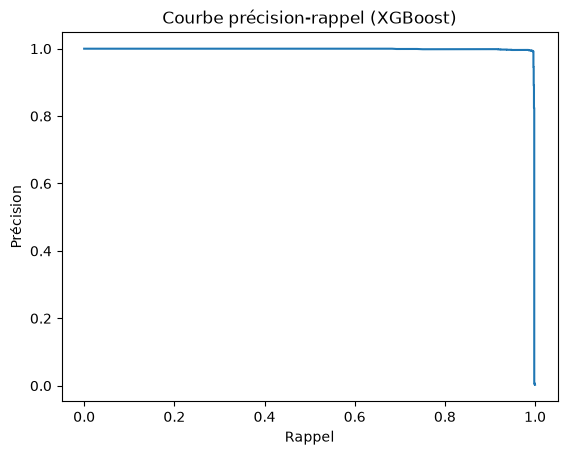

In [7]:
xgb = models["XGBoost"]
proba = xgb.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1s[:-1])
best_threshold = float(thr[best])
print(f"Meilleur seuil : {best_threshold:.3f}")
print(f"Précision : {prec[best]:.4f} | Rappel : {rec[best]:.4f} | F1 : {f1s[best]:.4f}")

plt.plot(rec, prec)
plt.xlabel("Rappel"); plt.ylabel("Précision")
plt.title("Courbe précision-rappel (XGBoost)")
plt.show()

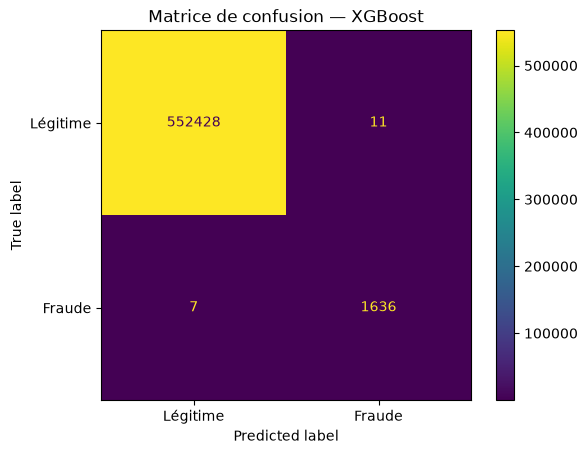

In [8]:
pred = (proba >= best_threshold).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Légitime", "Fraude"]).plot(values_format="d")
plt.title("Matrice de confusion — XGBoost")
plt.show()

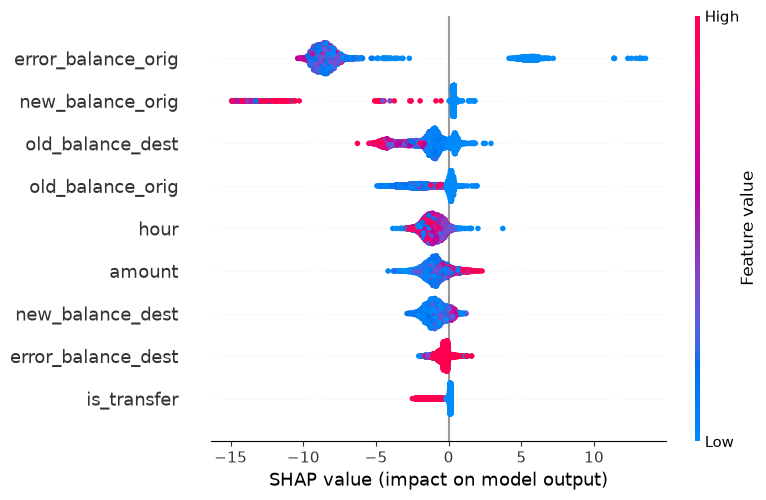

In [9]:
import shap

explainer = shap.TreeExplainer(xgb)
sample = X_test.sample(5000, random_state=42)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample)

In [10]:
os.makedirs("models", exist_ok=True)
xgb.save_model("models/xgb_fraud.json")
with open("models/model_meta.json", "w") as f:
    json.dump({"features": FEATURES, "threshold": best_threshold}, f, indent=2)
print("Modèle sauvegardé dans ml/models/")

Modèle sauvegardé dans ml/models/


In [11]:
# Métriques réelles du modèle XGBoost sur le jeu de test, lues par le backend
# (GET /api/analyst/statistics -> page Statistiques)
from datetime import datetime, timezone

pred = (proba >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

metrics = {
    "model": "XGBoost",
    "dataset": "PaySim (TRANSFER + CASH_OUT)",
    "precision": round(float(precision_score(y_test, pred)), 4),
    "recall": round(float(recall_score(y_test, pred)), 4),
    "f1": round(float(f1_score(y_test, pred)), 4),
    "auc_pr": round(float(average_precision_score(y_test, proba)), 4),
    "threshold": round(best_threshold, 6),
    "test_size": int(len(y_test)),
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    # Comparaison des 3 modèles (seuil 0,5, cellule d'entraînement)
    "models": [
        {
            "name": r["modèle"],
            "precision": float(r["précision"]),
            "recall": float(r["rappel"]),
            "f1": float(r["f1"]),
            "auc_pr": float(r["auc_pr"]),
        }
        for r in results
    ],
    "evaluated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}

os.makedirs("models", exist_ok=True)
with open("models/model_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print(json.dumps(metrics, indent=2, ensure_ascii=False))
print("Métriques sauvegardées dans ml/models/model_metrics.json")

{
  "model": "XGBoost",
  "dataset": "PaySim (TRANSFER + CASH_OUT)",
  "precision": 0.9933,
  "recall": 0.9957,
  "f1": 0.9945,
  "auc_pr": 0.9974,
  "threshold": 0.984088,
  "test_size": 554082,
  "confusion_matrix": {
    "tn": 552428,
    "fp": 11,
    "fn": 7,
    "tp": 1636
  },
  "models": [
    {
      "name": "Régression logistique",
      "precision": 0.0435,
      "recall": 0.8996,
      "f1": 0.0831,
      "auc_pr": 0.5751
    },
    {
      "name": "Random Forest",
      "precision": 1.0,
      "recall": 0.997,
      "f1": 0.9985,
      "auc_pr": 0.998
    },
    {
      "name": "XGBoost",
      "precision": 0.9909,
      "recall": 0.9963,
      "f1": 0.9936,
      "auc_pr": 0.9974
    }
  ],
  "evaluated_at": "2026-11-17T22:31:45+00:00"
}
Métriques sauvegardées dans ml/models/model_metrics.json
